In [1]:

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set visualization style
sns.set_theme(style='whitegrid')

# Define the project directory
project = Path('/content/Scientific_Visualisation')

# Create project folders
folders = [
    'datasets',
    'visualizations/maternal_death',
    'visualizations/life_expectancy',
    'visualizations/household_income'
]

# Create folders if they do not exist
for folder in folders:
    (project / folder).mkdir(parents=True, exist_ok=True)

# Display confirmation
print("Scientific Visualisation Project")
print("--------------------------------")
print("Libraries imported successfully!")
print("Project folders created successfully!")


Scientific Visualisation Project
--------------------------------
Libraries imported successfully!
Project folders created successfully!


In [2]:

# Load the maternal death dataset
df_maternal = pd.read_csv(
    project / 'datasets/death_maternal_state.csv'
)

# Display the first five rows
print("MATERNAL DEATH DATASET")
print("----------------------")
display(df_maternal.head())

# Display dataset shape
print("\nDataset Shape:", df_maternal.shape)

# Display column names
print("\nColumn Names:")
print(df_maternal.columns.tolist())


MATERNAL DEATH DATASET
----------------------


,state,date,abs,rate
0,Johor,2000-01-01,13,19.4
1,Johor,2001-01-01,9,14.7
2,Johor,2002-01-01,12,20.1
3,Johor,2003-01-01,11,18.9
4,Johor,2004-01-01,14,24.4



Dataset Shape: (406, 4)

Column Names:
['state', 'date', 'abs', 'rate']


In [3]:

# Display dataset information
print("DATASET INFORMATION")
print("-------------------")
df_maternal.info()

# Check for missing values
print("\nMISSING VALUES")
print("--------------")
print(df_maternal.isnull().sum())

# Check for duplicate records
print("\nDUPLICATE RECORDS")
print("-----------------")
print(df_maternal.duplicated().sum())

# Display unique states
print("\nUNIQUE STATES")
print("-------------")
print(df_maternal['state'].unique())

# Display summary statistics
print("\nSUMMARY STATISTICS")
print("------------------")
display(df_maternal.describe())


DATASET INFORMATION
-------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 406 entries, 0 to 405
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   state   406 non-null    object 
 1   date    406 non-null    object 
 2   abs     406 non-null    int64  
 3   rate    406 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 12.8+ KB

MISSING VALUES
--------------
state    0
date     0
abs      0
rate     0
dtype: int64

DUPLICATE RECORDS
-----------------
0

UNIQUE STATES
-------------
['Johor' 'Kedah' 'Kelantan' 'Melaka' 'Negeri Sembilan' 'Pahang' 'Perak'
 'Perlis' 'Pulau Pinang' 'Sabah' 'Sarawak' 'Selangor' 'Terengganu'
 'W.P. Kuala Lumpur' 'W.P. Labuan' 'W.P. Putrajaya']

SUMMARY STATISTICS
------------------


,abs,rate
count,406.000000,406.000000
mean,8.440887,27.587685
std,7.792380,25.817648
min,0.000000,0.000000
25%,3.000000,17.300000
50%,7.000000,23.900000
75%,12.000000,33.575000
max,80.000000,328.500000


In [4]:

# Create a copy of the original dataset
maternal_clean = df_maternal.copy()

# Convert the date column to datetime format
maternal_clean['date'] = pd.to_datetime(
    maternal_clean['date']
)

# Extract the year from the date column
maternal_clean['year'] = maternal_clean['date'].dt.year

# Sort the dataset by state and year
maternal_clean = maternal_clean.sort_values(
    by=['state', 'year']
).reset_index(drop=True)

# Display the cleaned dataset information
print("CLEANED MATERNAL DEATH DATASET")
print("------------------------------")

# Display dataset shape
print("Dataset Shape:", maternal_clean.shape)

# Display data types
print("\nData Types:")
print(maternal_clean.dtypes)

# Display available years
print("\nAvailable Years:")
print(sorted(maternal_clean['year'].unique()))

# Display the first five rows
print("\nFirst Five Rows:")
display(maternal_clean.head())


CLEANED MATERNAL DEATH DATASET
------------------------------
Dataset Shape: (406, 5)

Data Types:
state            object
date     datetime64[ns]
abs               int64
rate            float64
year              int32
dtype: object

Available Years:
[np.int32(2000), np.int32(2001), np.int32(2002), np.int32(2003), np.int32(2004), np.int32(2005), np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

First Five Rows:


,state,date,abs,rate,year
0,Johor,2000-01-01,13,19.4,2000
1,Johor,2001-01-01,9,14.7,2001
2,Johor,2002-01-01,12,20.1,2002
3,Johor,2003-01-01,11,18.9,2003
4,Johor,2004-01-01,14,24.4,2004


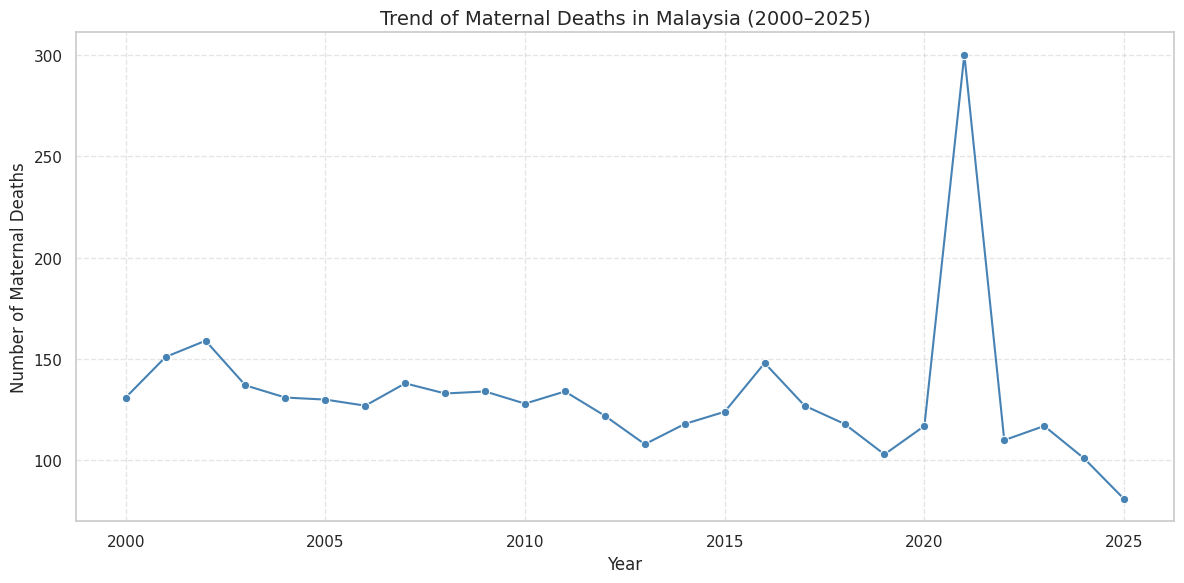

Line chart saved successfully!


In [5]:

# Calculate total maternal deaths for each year
maternal_trend = (
    maternal_clean.groupby('year')['abs']
    .sum()
    .reset_index()
)

# Create a line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=maternal_trend,
    x='year',
    y='abs',
    marker='o',
    color='steelblue'
)

# Add chart title and axis labels
plt.title(
    'Trend of Maternal Deaths in Malaysia (2000–2025)',
    fontsize=14
)
plt.xlabel('Year')
plt.ylabel('Number of Maternal Deaths')

# Improve chart layout
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save the chart in the project folder
plt.savefig(
    project / 'visualizations/maternal_death/maternal_deaths_lineplot.png',
    dpi=300,
    bbox_inches='tight'
)

# Display the chart
plt.show()

print("Line chart saved successfully!")


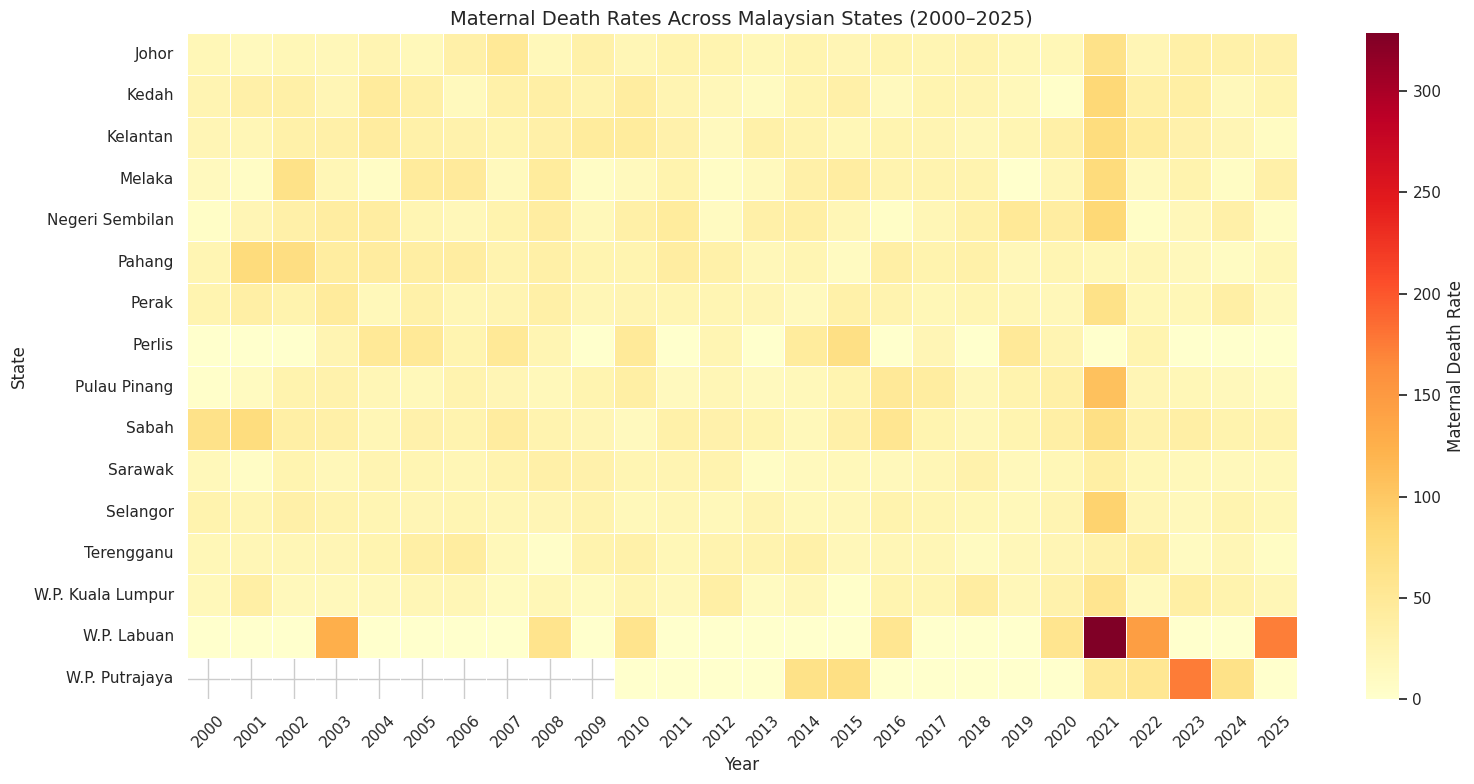

Heatmap saved successfully!


In [6]:

# Prepare data for the heatmap
maternal_heatmap = maternal_clean.pivot_table(
    index='state',
    columns='year',
    values='rate',
    aggfunc='mean'
)

# Create a heatmap
plt.figure(figsize=(16, 8))

sns.heatmap(
    maternal_heatmap,
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Maternal Death Rate'}
)

# Add chart title and axis labels
plt.title(
    'Maternal Death Rates Across Malaysian States (2000–2025)',
    fontsize=14
)
plt.xlabel('Year')
plt.ylabel('State')

# Improve chart layout
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

# Save the heatmap in the project folder
plt.savefig(
    project / 'visualizations/maternal_death/maternal_death_rates_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

# Display the heatmap
plt.show()

print("Heatmap saved successfully!")


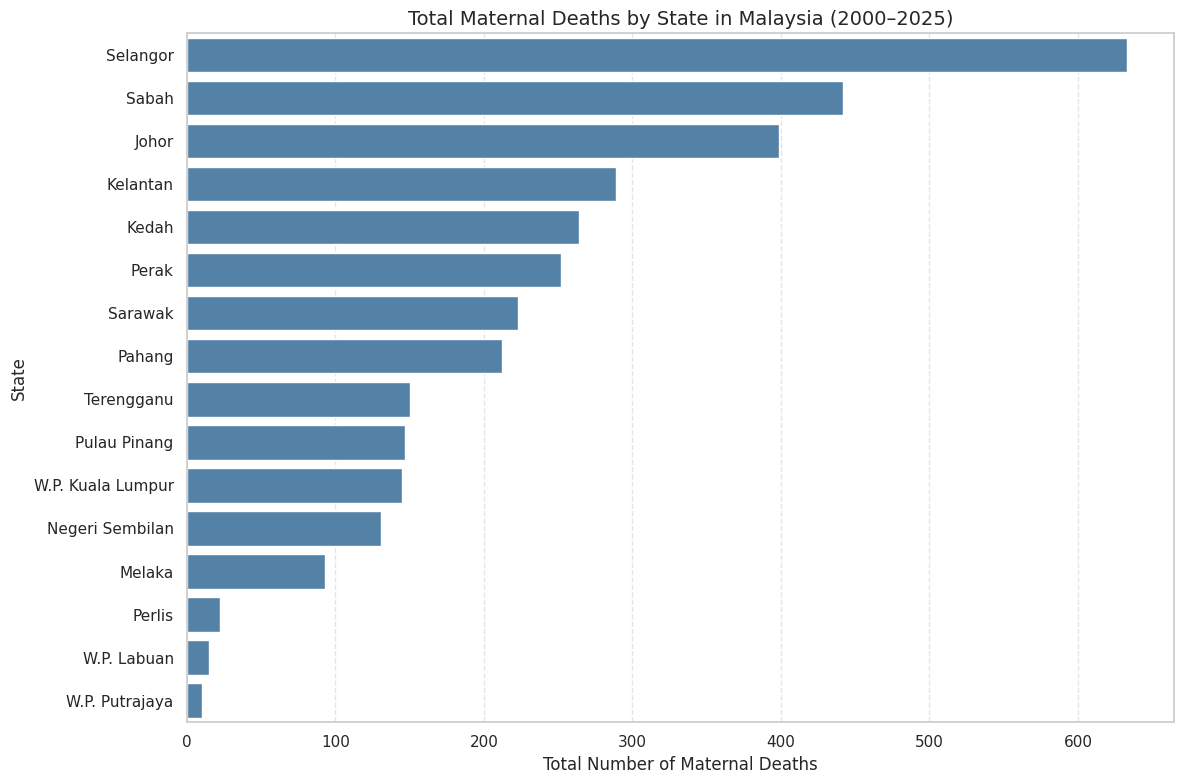

Horizontal bar chart saved successfully!


In [7]:

# Calculate total maternal deaths by state
state_deaths = (
    maternal_clean.groupby('state')['abs']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 8))

sns.barplot(
    data=state_deaths,
    x='abs',
    y='state',
    color='steelblue'
)

# Add chart title and axis labels
plt.title(
    'Total Maternal Deaths by State in Malaysia (2000–2025)',
    fontsize=14
)
plt.xlabel('Total Number of Maternal Deaths')
plt.ylabel('State')

# Improve chart layout
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

# Save the chart in the project folder
plt.savefig(
    project / 'visualizations/maternal_death/maternal_deaths_by_state.png',
    dpi=300,
    bbox_inches='tight'
)

# Display the chart
plt.show()

print("Horizontal bar chart saved successfully!")


In [8]:

# Calculate total maternal deaths
total_deaths = maternal_clean['abs'].sum()

# Calculate average annual maternal deaths
annual_deaths = maternal_clean.groupby('year')['abs'].sum()
average_annual = annual_deaths.mean()

# Calculate total maternal deaths by state
state_totals = (
    maternal_clean.groupby('state')['abs']
    .sum()
    .sort_values(ascending=False)
)

# Identify states with highest and lowest total deaths
highest_state = state_totals.idxmax()
lowest_state = state_totals.idxmin()

# Identify the highest recorded maternal death rate
highest_rate = maternal_clean['rate'].max()

# Create a summary statistics table
maternal_summary = pd.DataFrame({
    'Indicator': [
        'Total Maternal Deaths',
        'Average Annual Maternal Deaths',
        'Highest Maternal Deaths (State)',
        'Lowest Maternal Deaths (State)',
        'Highest Recorded Maternal Death Rate',
        'Analysis Period'
    ],
    'Value': [
        f'{total_deaths:,}',
        f'{average_annual:.2f}',
        f'{highest_state} ({state_totals.max():,})',
        f'{lowest_state} ({state_totals.min():,})',
        f'{highest_rate:.2f}',
        '2000–2025'
    ]
})

# Display the summary table
print("MATERNAL DEATH SUMMARY STATISTICS")
print("---------------------------------")
display(maternal_summary)

# Save the summary table as CSV
maternal_summary.to_csv(
    project / 'datasets/maternal_summary.csv',
    index=False
)

print("Summary table saved successfully!")


MATERNAL DEATH SUMMARY STATISTICS
---------------------------------


,Indicator,Value
0,Total Maternal Deaths,"3,427"
1,Average Annual Maternal Deaths,131.81
2,Highest Maternal Deaths (State),Selangor (633)
3,Lowest Maternal Deaths (State),W.P. Putrajaya (10)
4,Highest Recorded Maternal Death Rate,328.50
5,Analysis Period,2000–2025


Summary table saved successfully!


In [9]:

# Load the life expectancy dataset
df_life = pd.read_csv(
    project / 'datasets/life_expectancy_state_ethnic.csv'
)

# Display the first five rows
print("LIFE EXPECTANCY DATASET")
print("-----------------------")
display(df_life.head())

# Display dataset shape
print("\nDataset Shape:", df_life.shape)

# Display column names
print("\nColumn Names:")
print(df_life.columns.tolist())


LIFE EXPECTANCY DATASET
-----------------------


,state,date,sex,ethnicity,life_expectancy
0,Johor,2022-01-01,both,overall,73.5
1,Johor,2022-01-01,both,bumi,72.2
2,Johor,2022-01-01,both,bumi_malay,72.2
3,Johor,2022-01-01,both,bumi_other,72.4
4,Johor,2022-01-01,both,chinese,75.6



Dataset Shape: (1790, 5)

Column Names:
['state', 'date', 'sex', 'ethnicity', 'life_expectancy']


In [10]:

# Display dataset information
print("DATASET INFORMATION")
print("-------------------")
df_life.info()

# Check for missing values
print("\nMISSING VALUES")
print("--------------")
print(df_life.isnull().sum())

# Check for duplicate records
print("\nDUPLICATE RECORDS")
print("-----------------")
print(df_life.duplicated().sum())

# Display unique gender categories
print("\nUNIQUE GENDER CATEGORIES")
print("------------------------")
print(df_life['sex'].unique())

# Display unique ethnic groups
print("\nUNIQUE ETHNIC GROUPS")
print("--------------------")
print(df_life['ethnicity'].unique())

# Display unique states
print("\nUNIQUE STATES")
print("-------------")
print(df_life['state'].unique())

# Display summary statistics
print("\nSUMMARY STATISTICS")
print("------------------")
display(df_life.describe())


DATASET INFORMATION
-------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1790 entries, 0 to 1789
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   state            1790 non-null   object 
 1   date             1790 non-null   object 
 2   sex              1790 non-null   object 
 3   ethnicity        1790 non-null   object 
 4   life_expectancy  1790 non-null   float64
dtypes: float64(1), object(4)
memory usage: 70.1+ KB

MISSING VALUES
--------------
state              0
date               0
sex                0
ethnicity          0
life_expectancy    0
dtype: int64

DUPLICATE RECORDS
-----------------
0

UNIQUE GENDER CATEGORIES
------------------------
['both' 'male' 'female']

UNIQUE ETHNIC GROUPS
--------------------
['overall' 'bumi' 'bumi_malay' 'bumi_other' 'chinese' 'indian' 'citizen'
 'noncitizen']

UNIQUE STATES
-------------
['Johor' 'Kedah' 'Kelantan' 'Melaka' 'Negeri Sembilan' 

,life_expectancy
count,1790.000000
mean,74.061788
std,4.010389
min,55.200000
25%,71.300000
50%,74.100000
75%,76.500000
max,87.500000


In [11]:

# Create a copy of the original dataset
life_clean = df_life.copy()

# Convert the date column to datetime format
life_clean['date'] = pd.to_datetime(
    life_clean['date']
)

# Extract the year from the date column
life_clean['year'] = life_clean['date'].dt.year

# Sort the dataset by state and year
life_clean = life_clean.sort_values(
    by=['state', 'year']
).reset_index(drop=True)

# Display cleaned dataset information
print("CLEANED LIFE EXPECTANCY DATASET")
print("-------------------------------")

# Display dataset shape
print("Dataset Shape:", life_clean.shape)

# Display data types
print("\nData Types:")
print(life_clean.dtypes)

# Display available years
print("\nAvailable Years:")
print(sorted(life_clean['year'].unique()))

# Display the first five rows
print("\nFirst Five Rows:")
display(life_clean.head())


CLEANED LIFE EXPECTANCY DATASET
-------------------------------
Dataset Shape: (1790, 6)

Data Types:
state                      object
date               datetime64[ns]
sex                        object
ethnicity                  object
life_expectancy           float64
year                        int32
dtype: object

Available Years:
[np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]

First Five Rows:


,state,date,sex,ethnicity,life_expectancy,year
0,Johor,2022-01-01,both,overall,73.5,2022
1,Johor,2022-01-01,both,bumi,72.2,2022
2,Johor,2022-01-01,both,bumi_malay,72.2,2022
3,Johor,2022-01-01,both,bumi_other,72.4,2022
4,Johor,2022-01-01,both,chinese,75.6,2022


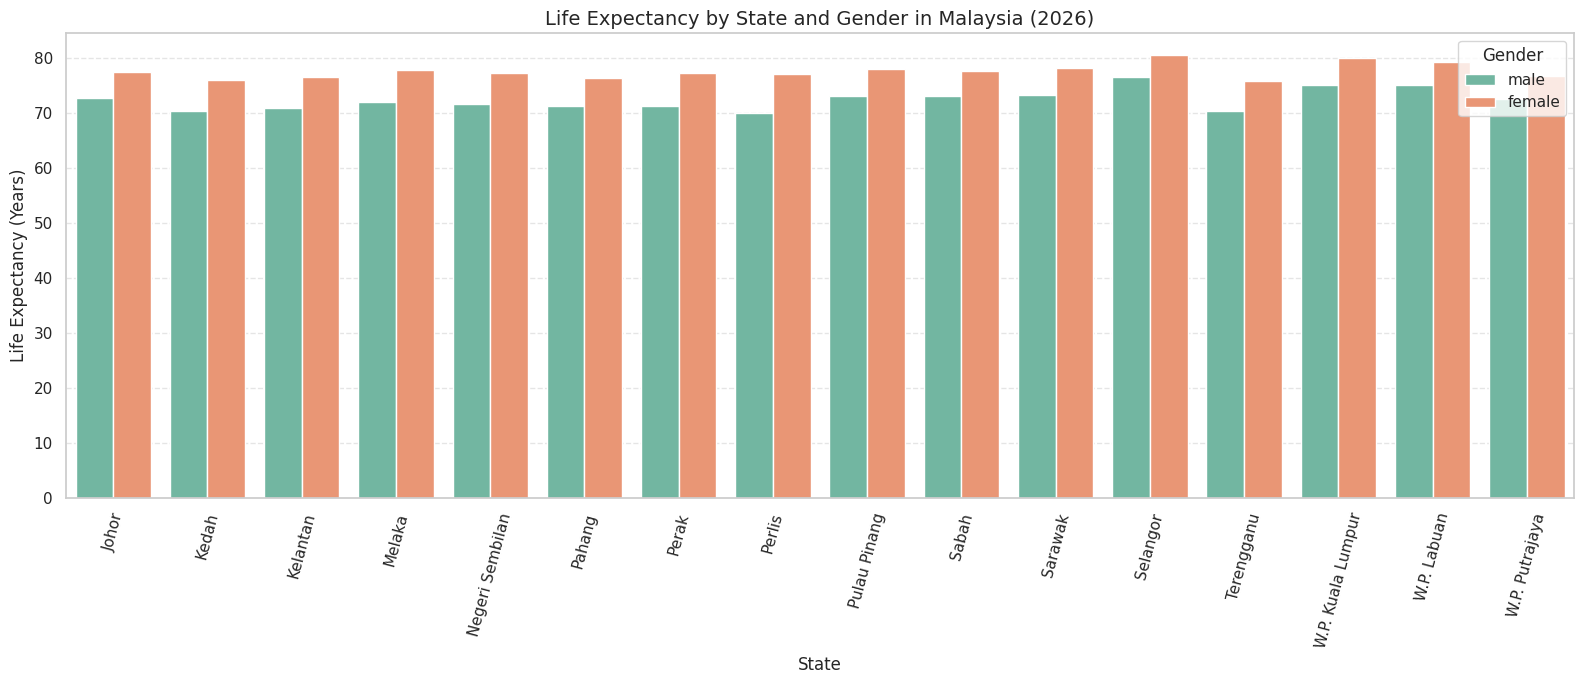

Grouped bar chart saved successfully!


In [12]:

# OBJECTIVE 1: LIFE EXPECTANCY BY STATE AND GENDER

# Filter data for 2026 and overall ethnicity
life_gender = life_clean[
    (life_clean['year'] == 2026) &
    (life_clean['ethnicity'] == 'overall') &
    (life_clean['sex'].isin(['male', 'female']))
].copy()

# Create grouped bar chart
plt.figure(figsize=(16, 7))

sns.barplot(
    data=life_gender,
    x='state',
    y='life_expectancy',
    hue='sex',
    palette='Set2',
    errorbar=None
)

# Add chart title and labels
plt.title(
    'Life Expectancy by State and Gender in Malaysia (2026)',
    fontsize=14
)
plt.xlabel('State')
plt.ylabel('Life Expectancy (Years)')
plt.xticks(rotation=75)
plt.legend(title='Gender')

# Improve chart layout
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# Save chart in the project folder
plt.savefig(
    project / 'visualizations/life_expectancy/life_expectancy_gender_2026.png',
    dpi=300,
    bbox_inches='tight'
)

# Display chart
plt.show()

print("Grouped bar chart saved successfully!")


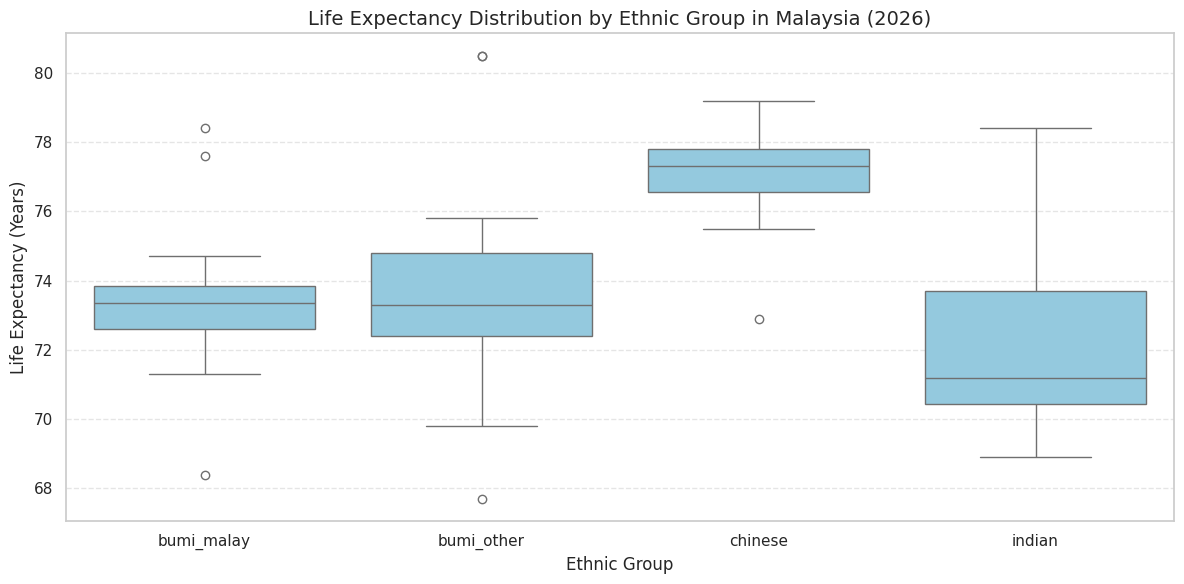

Box plot saved successfully!


In [13]:

# OBJECTIVE 2: LIFE EXPECTANCY BY ETHNIC GROUP

# Filter data for 2026 and both genders
life_ethnicity = life_clean[
    (life_clean['year'] == 2026) &
    (life_clean['sex'] == 'both') &
    (life_clean['ethnicity'].isin([
        'bumi_malay', 'bumi_other',
        'chinese', 'indian'
    ]))
].copy()

# Create box plot
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=life_ethnicity,
    x='ethnicity',
    y='life_expectancy',
    color='skyblue'
)

# Add chart title and labels
plt.title(
    'Life Expectancy Distribution by Ethnic Group in Malaysia (2026)',
    fontsize=14
)
plt.xlabel('Ethnic Group')
plt.ylabel('Life Expectancy (Years)')

# Improve chart layout
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# Save chart
plt.savefig(
    project / 'visualizations/life_expectancy/life_expectancy_ethnicity_2026.png',
    dpi=300,
    bbox_inches='tight'
)

# Display chart
plt.show()

print("Box plot saved successfully!")


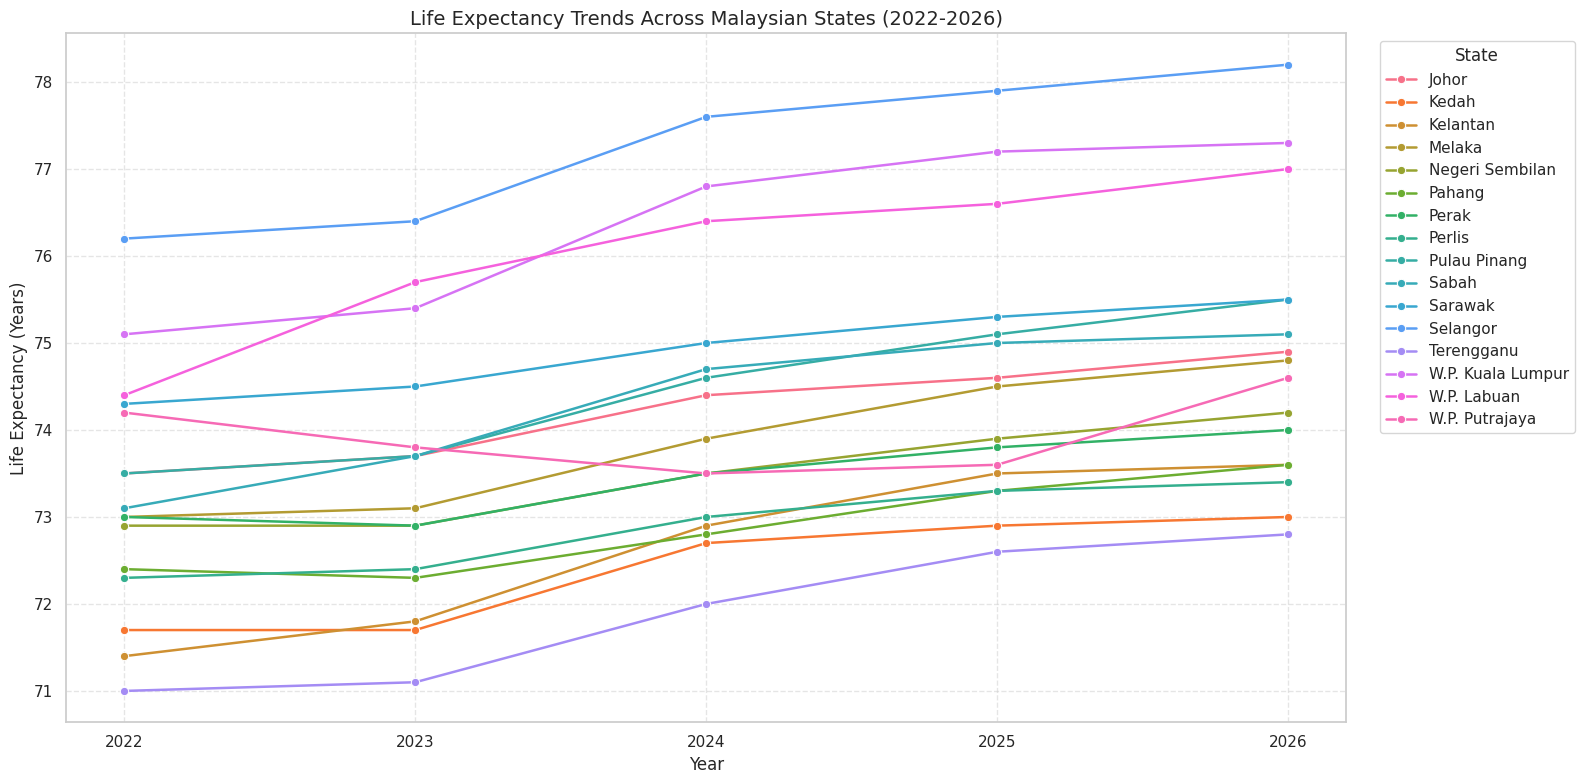

Line chart saved successfully!


In [14]:

# OBJECTIVE 3: LIFE EXPECTANCY TRENDS BY STATE

# Filter overall life expectancy for both genders
life_trends = life_clean[
    (life_clean['sex'] == 'both') &
    (life_clean['ethnicity'] == 'overall')
].copy()

# Create line chart
plt.figure(figsize=(16, 8))

sns.lineplot(
    data=life_trends,
    x='year',
    y='life_expectancy',
    hue='state',
    marker='o',
    linewidth=1.8
)

# Add chart title and labels
plt.title(
    'Life Expectancy Trends Across Malaysian States (2022-2026)',
    fontsize=14
)
plt.xlabel('Year')
plt.ylabel('Life Expectancy (Years)')
plt.xticks([2022, 2023, 2024, 2025, 2026])

# Position legend outside the chart
plt.legend(
    title='State',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

# Improve chart layout
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save chart
plt.savefig(
    project / 'visualizations/life_expectancy/life_expectancy_trends_2022_2026.png',
    dpi=300,
    bbox_inches='tight'
)

# Display chart
plt.show()

print("Line chart saved successfully!")


In [15]:

# STEP 13: LIFE EXPECTANCY SUMMARY STATISTICS

# Filter overall life expectancy for 2026
life_summary_data = life_clean[
    (life_clean['year'] == 2026) &
    (life_clean['sex'] == 'both') &
    (life_clean['ethnicity'] == 'overall')
].copy()

# Calculate summary statistics
average_life = life_summary_data['life_expectancy'].mean()

highest_life = life_summary_data.loc[
    life_summary_data['life_expectancy'].idxmax()
]

lowest_life = life_summary_data.loc[
    life_summary_data['life_expectancy'].idxmin()
]

# Create summary table
life_summary = pd.DataFrame({
    'Indicator': [
        'Average State Life Expectancy',
        'Highest Life Expectancy (State)',
        'Lowest Life Expectancy (State)',
        'Analysis Period'
    ],
    'Value': [
        f'{average_life:.2f} years',
        f"{highest_life['state']} ({highest_life['life_expectancy']:.1f} years)",
        f"{lowest_life['state']} ({lowest_life['life_expectancy']:.1f} years)",
        '2022-2026'
    ]
})

# Display summary table
print("LIFE EXPECTANCY SUMMARY STATISTICS")
print("--------------------------------")
display(life_summary)

# Save summary table as CSV
life_summary.to_csv(
    project / 'datasets/life_expectancy_summary.csv',
    index=False
)

print("Summary table saved successfully!")


LIFE EXPECTANCY SUMMARY STATISTICS
--------------------------------


,Indicator,Value
0,Average State Life Expectancy,74.84 years
1,Highest Life Expectancy (State),Selangor (78.2 years)
2,Lowest Life Expectancy (State),Terengganu (72.8 years)
3,Analysis Period,2022-2026


Summary table saved successfully!


In [16]:

# STEP 14.1: LOAD HOUSEHOLD INCOME DATASET

# Load the household income dataset
df_income = pd.read_csv(
    project / 'datasets/hies_state_percentile.csv'
)

# Display the first five rows
print("HOUSEHOLD INCOME DATASET")
print("------------------------")
display(df_income.head())

# Display dataset shape
print("\nDataset Shape:", df_income.shape)

# Display column names
print("\nColumn Names:")
print(df_income.columns.tolist())


HOUSEHOLD INCOME DATASET
------------------------


,date,state,percentile,variable,income
0,2024-01-01,Johor,1,mean,1638.0
1,2024-01-01,Johor,1,median,1682.0
2,2024-01-01,Johor,1,minimum,NaN
3,2024-01-01,Johor,1,maximum,1912.0
4,2024-01-01,Johor,2,mean,2076.0



Dataset Shape: (19200, 5)

Column Names:
['date', 'state', 'percentile', 'variable', 'income']


In [17]:

# STEP 14.2: HOUSEHOLD INCOME DATA EXPLORATION

# Display dataset information
print("DATASET INFORMATION")
print("-------------------")
df_income.info()

# Check missing values
print("\nMISSING VALUES")
print("--------------")
print(df_income.isnull().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS")
print("-----------------")
print(df_income.duplicated().sum())

# Display unique income variables
print("\nUNIQUE INCOME VARIABLES")
print("-----------------------")
print(df_income['variable'].unique())

# Display available dates
print("\nAVAILABLE DATES")
print("---------------")
print(df_income['date'].unique())

# Display available percentiles
print("\nAVAILABLE PERCENTILES")
print("---------------------")
print(sorted(df_income['percentile'].unique()))

# Display unique states
print("\nUNIQUE STATES")
print("-------------")
print(df_income['state'].unique())

# Display summary statistics
print("\nSUMMARY STATISTICS")
print("------------------")
display(df_income.describe())


DATASET INFORMATION
-------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19200 entries, 0 to 19199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        19200 non-null  object 
 1   state       19200 non-null  object 
 2   percentile  19200 non-null  int64  
 3   variable    19200 non-null  object 
 4   income      19104 non-null  float64
dtypes: float64(1), int64(1), object(3)
memory usage: 750.1+ KB

MISSING VALUES
--------------
date           0
state          0
percentile     0
variable       0
income        96
dtype: int64

DUPLICATE RECORDS
-----------------
0

UNIQUE INCOME VARIABLES
-----------------------
['mean' 'median' 'minimum' 'maximum']

AVAILABLE DATES
---------------
['2024-01-01' '2022-01-01' '2019-01-01']

AVAILABLE PERCENTILES
---------------------
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(

,percentile,income
count,19200.000000,19104.000000
mean,50.500000,7846.173733
std,28.866822,6654.839384
min,1.000000,740.000000
25%,25.750000,3753.250000
50%,50.500000,6005.000000
75%,75.250000,9741.000000
max,100.000000,131441.000000


In [18]:

# STEP 14.3: HOUSEHOLD INCOME DATA PREPROCESSING

# Create a copy of the original dataset
income_clean = df_income.copy()

# Convert date column to datetime format
income_clean['date'] = pd.to_datetime(
    income_clean['date']
)

# Extract year from date
income_clean['year'] = income_clean['date'].dt.year

# Check missing values by income variable
print("MISSING VALUES BY INCOME VARIABLE")
print("---------------------------------")
print(
    income_clean.groupby('variable')['income']
    .apply(lambda x: x.isnull().sum())
)

# Remove rows with missing income values
income_clean = income_clean.dropna(
    subset=['income']
)

# Display cleaned dataset information
print("\nCLEANED HOUSEHOLD INCOME DATASET")
print("--------------------------------")
print("Dataset Shape:", income_clean.shape)

# Display data types
print("\nData Types:")
print(income_clean.dtypes)

# Display available years
print("\nAvailable Years:")
print(sorted(income_clean['year'].unique()))

# Display first five rows
print("\nFirst Five Rows:")
display(income_clean.head())


MISSING VALUES BY INCOME VARIABLE
---------------------------------
variable
maximum    48
mean        0
median      0
minimum    48
Name: income, dtype: int64

CLEANED HOUSEHOLD INCOME DATASET
--------------------------------
Dataset Shape: (19104, 6)

Data Types:
date          datetime64[ns]
state                 object
percentile             int64
variable              object
income               float64
year                   int32
dtype: object

Available Years:
[np.int32(2019), np.int32(2022), np.int32(2024)]

First Five Rows:


,date,state,percentile,variable,income,year
0,2024-01-01,Johor,1,mean,1638.0,2024
1,2024-01-01,Johor,1,median,1682.0,2024
3,2024-01-01,Johor,1,maximum,1912.0,2024
4,2024-01-01,Johor,2,mean,2076.0,2024
5,2024-01-01,Johor,2,median,2084.0,2024


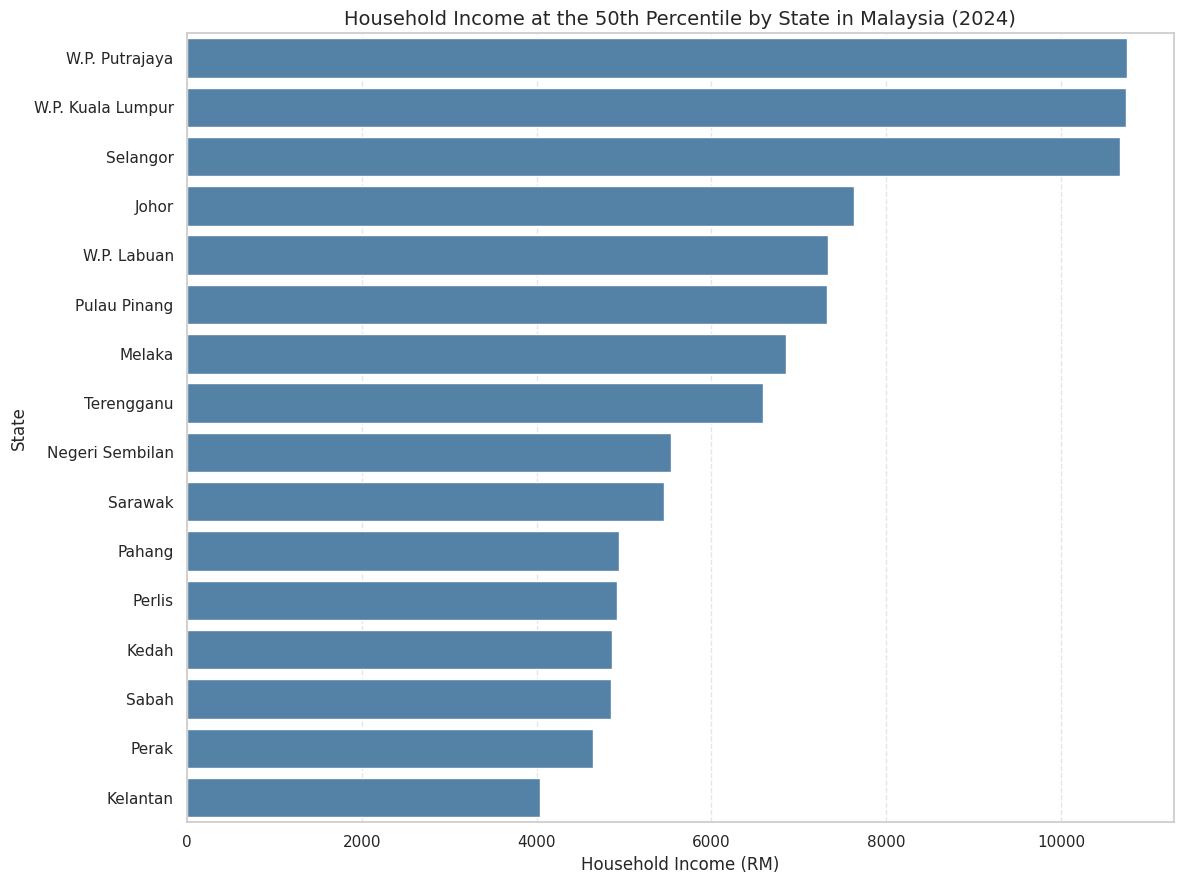

Horizontal bar chart saved successfully!


In [19]:

# STEP 15: HOUSEHOLD INCOME OBJECTIVE 1
# Household Income at the 50th Percentile by State

# Filter data for 2024, median and 50th percentile
income_50 = income_clean[
    (income_clean['year'] == 2024) &
    (income_clean['variable'] == 'median') &
    (income_clean['percentile'] == 50)
].copy()

# Sort household income in descending order
income_50 = income_50.sort_values(
    by='income',
    ascending=False
)

# Create horizontal bar chart
plt.figure(figsize=(12, 9))

sns.barplot(
    data=income_50,
    x='income',
    y='state',
    color='steelblue'
)

# Add chart title and labels
plt.title(
    'Household Income at the 50th Percentile by State in Malaysia (2024)',
    fontsize=14
)
plt.xlabel('Household Income (RM)')
plt.ylabel('State')

# Improve chart layout
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

# Save chart in project folder
plt.savefig(
    project / 'visualizations/household_income/household_income_50th_percentile_2024.png',
    dpi=300,
    bbox_inches='tight'
)

# Display chart
plt.show()

print("Horizontal bar chart saved successfully!")


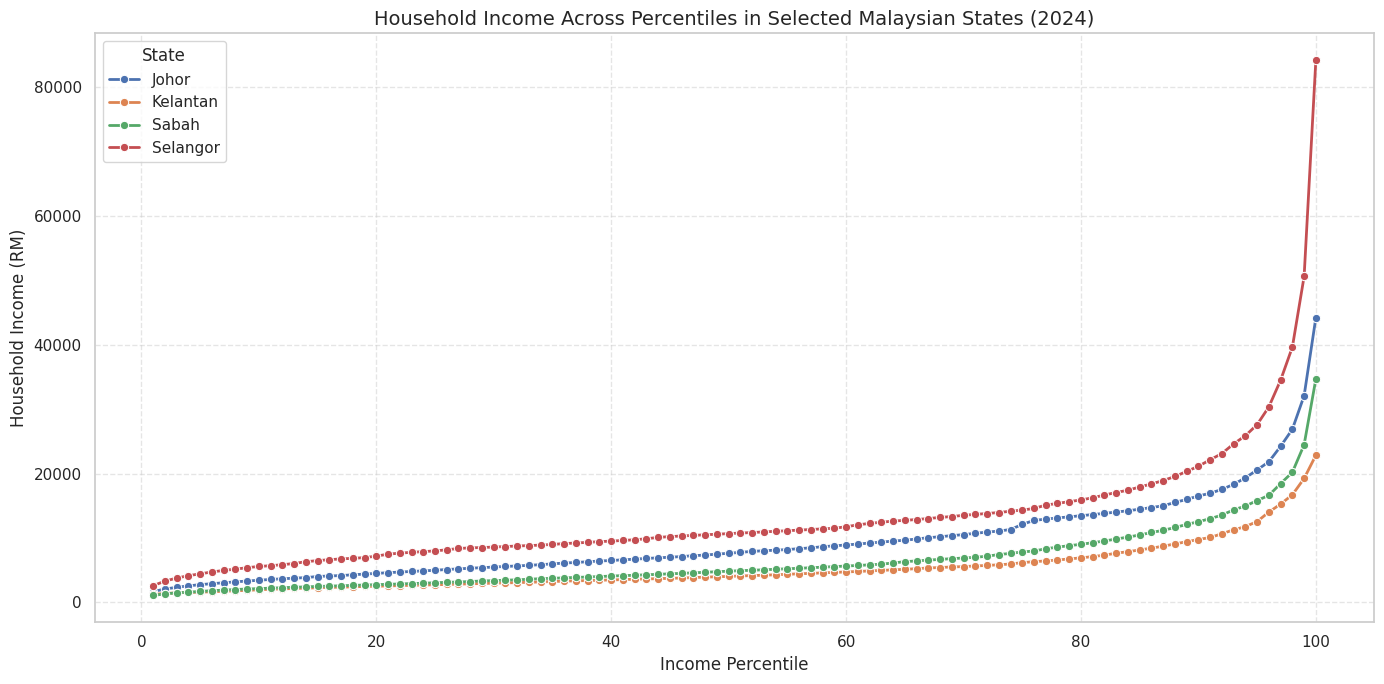

Multi-line chart saved successfully!


In [20]:

# STEP 16: HOUSEHOLD INCOME OBJECTIVE 2
# Household Income Across Percentiles

# Select states for comparison
selected_states = [
    'Johor', 'Kelantan', 'Sabah', 'Selangor'
]

# Filter income data for 2024
income_percentiles = income_clean[
    (income_clean['year'] == 2024) &
    (income_clean['variable'] == 'median') &
    (income_clean['state'].isin(selected_states))
].copy()

# Create multi-line chart
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=income_percentiles,
    x='percentile',
    y='income',
    hue='state',
    marker='o',
    linewidth=2
)

# Add chart title and labels
plt.title(
    'Household Income Across Percentiles in Selected Malaysian States (2024)',
    fontsize=14
)
plt.xlabel('Income Percentile')
plt.ylabel('Household Income (RM)')
plt.legend(title='State')

# Improve chart layout
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save chart
plt.savefig(
    project / 'visualizations/household_income/household_income_percentiles_2024.png',
    dpi=300,
    bbox_inches='tight'
)

# Display chart
plt.show()

print("Multi-line chart saved successfully!")


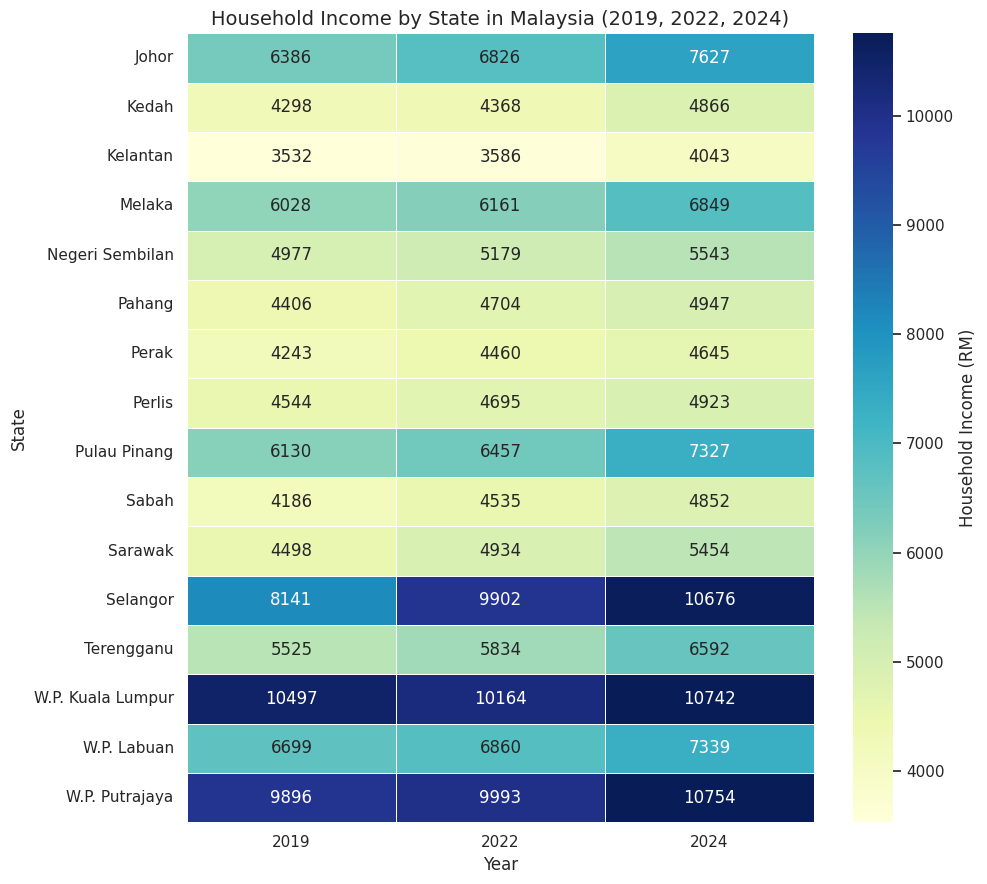

Household income heatmap saved successfully!


In [21]:

# STEP 17: HOUSEHOLD INCOME OBJECTIVE 3
# Household Income Heatmap (2019, 2022, 2024)

# Filter median household income at 50th percentile
income_heatmap_data = income_clean[
    (income_clean['variable'] == 'median') &
    (income_clean['percentile'] == 50) &
    (income_clean['year'].isin([2019, 2022, 2024]))
].copy()

# Prepare data for heatmap
income_pivot = income_heatmap_data.pivot(
    index='state',
    columns='year',
    values='income'
)

# Arrange years in chronological order
income_pivot = income_pivot[[2019, 2022, 2024]]

# Create heatmap
plt.figure(figsize=(10, 9))

sns.heatmap(
    income_pivot,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Household Income (RM)'}
)

# Add title and labels
plt.title(
    'Household Income by State in Malaysia (2019, 2022, 2024)',
    fontsize=14
)
plt.xlabel('Year')
plt.ylabel('State')

# Improve chart layout
plt.tight_layout()

# Save heatmap
plt.savefig(
    project / 'visualizations/household_income/household_income_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

# Display heatmap
plt.show()

print("Household income heatmap saved successfully!")


In [22]:

# STEP 18: HOUSEHOLD INCOME SUMMARY STATISTICS

# Filter household income data for 2024
# Use median income at the 50th percentile
income_summary_data = income_clean[
    (income_clean['year'] == 2024) &
    (income_clean['variable'] == 'median') &
    (income_clean['percentile'] == 50)
].copy()

# Calculate average income across states
average_income = income_summary_data['income'].mean()

# Identify highest and lowest income
highest_income = income_summary_data.loc[
    income_summary_data['income'].idxmax()
]

lowest_income = income_summary_data.loc[
    income_summary_data['income'].idxmin()
]

# Calculate income gap
income_gap = (
    highest_income['income'] -
    lowest_income['income']
)

# Create summary table
income_summary = pd.DataFrame({
    'Indicator': [
        'Average State Household Income',
        'Highest Household Income (State)',
        'Lowest Household Income (State)',
        'Income Gap',
        'Analysis Year'
    ],
    'Value': [
        f"RM {average_income:,.2f}",
        f"{highest_income['state']} (RM {highest_income['income']:,.2f})",
        f"{lowest_income['state']} (RM {lowest_income['income']:,.2f})",
        f"RM {income_gap:,.2f}",
        '2024'
    ]
})

# Display summary table
print("HOUSEHOLD INCOME SUMMARY STATISTICS")
print("-----------------------------------")
display(income_summary)

# Save summary table as CSV
income_summary.to_csv(
    project / 'datasets/household_income_summary.csv',
    index=False
)

print("Summary table saved successfully!")


HOUSEHOLD INCOME SUMMARY STATISTICS
-----------------------------------


,Indicator,Value
0,Average State Household Income,"RM 6,698.69"
1,Highest Household Income (State),"W.P. Putrajaya (RM 10,754.00)"
2,Lowest Household Income (State),"Kelantan (RM 4,043.00)"
3,Income Gap,"RM 6,711.00"
4,Analysis Year,2024


Summary table saved successfully!


In [23]:

# STEP 19: FINAL PROJECT FILE VERIFICATION

from pathlib import Path

# Define project directory
project = Path('/content/Scientific_Visualisation')

# Expected project files
expected_files = {
    'Datasets': [
        'datasets/death_maternal_state.csv',
        'datasets/life_expectancy_state_ethnic.csv',
        'datasets/hies_state_percentile.csv'
    ],
    'Maternal Death Visualizations': [
        'visualizations/maternal_death/maternal_deaths_lineplot.png',
        'visualizations/maternal_death/maternal_death_rates_heatmap.png',
        'visualizations/maternal_death/maternal_deaths_by_state.png'
    ],
    'Life Expectancy Visualizations': [
        'visualizations/life_expectancy/life_expectancy_gender_2026.png',
        'visualizations/life_expectancy/life_expectancy_ethnicity_2026.png',
        'visualizations/life_expectancy/life_expectancy_trends_2022_2026.png'
    ],
    'Household Income Visualizations': [
        'visualizations/household_income/household_income_barplot.png',
        'visualizations/household_income/household_income_lineplot.png',
        'visualizations/household_income/household_income_heatmap.png'
    ],
    'Summary Tables': [
        'datasets/maternal_summary.csv',
        'datasets/life_summary.csv',
        'datasets/household_income_summary.csv'
    ]
}

# Verify files
total_files = 0
found_files = 0

for category, files in expected_files.items():
    print(f"\n{category}")
    print("-" * 45)

    for filename in files:
        file_path = project / filename
        total_files += 1

        if file_path.is_file():
            print(f"FOUND   : {filename}")
            found_files += 1
        else:
            print(f"MISSING : {filename}")

# Display verification summary
print("\nFINAL PROJECT VERIFICATION")
print("-" * 45)
print(f"Total Expected Files : {total_files}")
print(f"Files Found          : {found_files}")
print(f"Files Missing        : {total_files - found_files}")

if found_files == total_files:
    print("\nAll project files verified successfully!")
else:
    print("\nSome files are missing. Please review the list.")



Datasets
---------------------------------------------
FOUND   : datasets/death_maternal_state.csv
FOUND   : datasets/life_expectancy_state_ethnic.csv
FOUND   : datasets/hies_state_percentile.csv

Maternal Death Visualizations
---------------------------------------------
FOUND   : visualizations/maternal_death/maternal_deaths_lineplot.png
FOUND   : visualizations/maternal_death/maternal_death_rates_heatmap.png
FOUND   : visualizations/maternal_death/maternal_deaths_by_state.png

Life Expectancy Visualizations
---------------------------------------------
FOUND   : visualizations/life_expectancy/life_expectancy_gender_2026.png
FOUND   : visualizations/life_expectancy/life_expectancy_ethnicity_2026.png
FOUND   : visualizations/life_expectancy/life_expectancy_trends_2022_2026.png

Household Income Visualizations
---------------------------------------------
MISSING : visualizations/household_income/household_income_barplot.png
MISSING : visualizations/household_income/household_income_l

In [24]:

# STEP 20: SEARCH FOR MISSING PROJECT FILES

from pathlib import Path

project = Path('/content/Scientific_Visualisation')

# Search for all PNG and CSV files
print("ALL PROJECT PNG AND CSV FILES")
print("-" * 50)

files = sorted(
    list(project.rglob('*.png')) +
    list(project.rglob('*.csv'))
)

for file in files:
    print(file.relative_to(project))

print("\nTotal files found:", len(files))

# Check household income visualization folder
print("\nHOUSEHOLD INCOME VISUALIZATIONS")
print("-" * 50)

income_folder = project / 'visualizations/household_income'

for file in sorted(income_folder.iterdir()):
    print(file.name)

# Check life expectancy summary files
print("\nLIFE EXPECTANCY SUMMARY FILES")
print("-" * 50)

for file in project.rglob('*life*summary*'):
    print(file.relative_to(project))


ALL PROJECT PNG AND CSV FILES
--------------------------------------------------
datasets/death_maternal_state.csv
datasets/hies_state_percentile.csv
datasets/household_income_summary.csv
datasets/life_expectancy_state_ethnic.csv
datasets/life_expectancy_summary.csv
datasets/maternal_summary.csv
visualizations/household_income/household_income_50th_percentile_2024.png
visualizations/household_income/household_income_heatmap.png
visualizations/household_income/household_income_percentiles_2024.png
visualizations/life_expectancy/life_expectancy_ethnicity_2026.png
visualizations/life_expectancy/life_expectancy_gender_2026.png
visualizations/life_expectancy/life_expectancy_trends_2022_2026.png
visualizations/maternal_death/maternal_death_rates_heatmap.png
visualizations/maternal_death/maternal_deaths_by_state.png
visualizations/maternal_death/maternal_deaths_lineplot.png

Total files found: 15

HOUSEHOLD INCOME VISUALIZATIONS
--------------------------------------------------
household_inc

In [25]:

# STEP 21: FINAL PROJECT VERIFICATION (CORRECTED)

from pathlib import Path

# Define project directory
project = Path('/content/Scientific_Visualisation')

# Define actual project files
expected_files = {
    'Datasets': [
        'datasets/death_maternal_state.csv',
        'datasets/life_expectancy_state_ethnic.csv',
        'datasets/hies_state_percentile.csv'
    ],

    'Maternal Death Visualizations': [
        'visualizations/maternal_death/maternal_deaths_lineplot.png',
        'visualizations/maternal_death/maternal_death_rates_heatmap.png',
        'visualizations/maternal_death/maternal_deaths_by_state.png'
    ],

    'Life Expectancy Visualizations': [
        'visualizations/life_expectancy/life_expectancy_gender_2026.png',
        'visualizations/life_expectancy/life_expectancy_ethnicity_2026.png',
        'visualizations/life_expectancy/life_expectancy_trends_2022_2026.png'
    ],

    'Household Income Visualizations': [
        'visualizations/household_income/household_income_50th_percentile_2024.png',
        'visualizations/household_income/household_income_percentiles_2024.png',
        'visualizations/household_income/household_income_heatmap.png'
    ],

    'Summary Tables': [
        'datasets/maternal_summary.csv',
        'datasets/life_expectancy_summary.csv',
        'datasets/household_income_summary.csv'
    ]
}

# Verify all project files
total_files = 0
found_files = 0

for category, files in expected_files.items():

    print(f"\n{category}")
    print("-" * 50)

    for filename in files:
        file_path = project / filename
        total_files += 1

        if file_path.is_file():
            print(f"FOUND   : {filename}")
            found_files += 1
        else:
            print(f"MISSING : {filename}")

# Display final verification summary
print("\nFINAL PROJECT VERIFICATION")
print("-" * 50)
print(f"Total Expected Files : {total_files}")
print(f"Files Found          : {found_files}")
print(f"Files Missing        : {total_files - found_files}")

if found_files == total_files:
    print("\nALL PROJECT FILES VERIFIED SUCCESSFULLY!")
else:
    print("\nSome files are missing.")



Datasets
--------------------------------------------------
FOUND   : datasets/death_maternal_state.csv
FOUND   : datasets/life_expectancy_state_ethnic.csv
FOUND   : datasets/hies_state_percentile.csv

Maternal Death Visualizations
--------------------------------------------------
FOUND   : visualizations/maternal_death/maternal_deaths_lineplot.png
FOUND   : visualizations/maternal_death/maternal_death_rates_heatmap.png
FOUND   : visualizations/maternal_death/maternal_deaths_by_state.png

Life Expectancy Visualizations
--------------------------------------------------
FOUND   : visualizations/life_expectancy/life_expectancy_gender_2026.png
FOUND   : visualizations/life_expectancy/life_expectancy_ethnicity_2026.png
FOUND   : visualizations/life_expectancy/life_expectancy_trends_2022_2026.png

Household Income Visualizations
--------------------------------------------------
FOUND   : visualizations/household_income/household_income_50th_percentile_2024.png
FOUND   : visualizations/ho

In [26]:

# STEP 22: CREATE FINAL PROJECT ZIP FILE

import shutil
from pathlib import Path
from google.colab import files

# Define project folder
project = Path('/content/Scientific_Visualisation')

# Define ZIP file location
zip_path = '/content/Scientific_Visualisation_Final'

# Create ZIP archive
shutil.make_archive(
    zip_path,
    'zip',
    root_dir='/content',
    base_dir='Scientific_Visualisation'
)

print("Project ZIP created successfully!")

# Download ZIP file
files.download(zip_path + '.zip')


Project ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>